In [134]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math
import datetime
import glob

import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.transforms as mtransforms
import matplotlib.ticker as ticker

from dask.diagnostics import ProgressBar
import dask.array as da

import os
os.chdir('/jetfs/home/psplechtna/msc_thesis/analysis/')

from utils import *

In [135]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [136]:
run='oper/2024/oper_01'

In [137]:
# define flexpart output file path
path = '/jetfs/scratch/psplechtna/flexpart_output/'+run+'/'
filename_gridded = glob.glob(os.path.join(path, 'grid_time_*.nc'))[0]

# climatology path
path_clim = "/jetfs/scratch/psplechtna/thesisdata/mse_climatology_4.0/"
filename_clim = "mse_hourly_climatology.zarr"

# partinit file - diagnostics at time of particle release
filename_partinit = glob.glob(os.path.join(path, 'partinit_*.nc'))[0]

# pre-saved data from pre-processing
path_pre = '/jetfs/scratch/psplechtna/flexpart_output/'+run+'/processed_data/'

filename_lh = 'lh_bl.zarr'
filename_sh = 'sh_bl.zarr'
filename_sw = 'rad_sw.zarr'
filename_lw = 'rad_lw.zarr'
filename_tot = 'total_mse.zarr'
filename_seas = 'season.zarr'

# initial conditions
filename_init_conds = 'initial_conditions.nc'

In [138]:
# load data sets
gridded = xr.open_dataset(filename_gridded, chunks={'time': 200})
partinit = xr.open_dataset(filename_partinit)
#part = xr.open_mfdataset(path+filename_particle)

rel_lh = xr.open_mfdataset(path_pre+filename_lh, engine='zarr', concat_dim='time', combine='nested').load()
rel_sh = xr.open_mfdataset(path_pre+filename_sh, engine='zarr', concat_dim='time', combine='nested').load()
rel_sw = xr.open_mfdataset(path_pre+filename_sw, engine='zarr', concat_dim='time', combine='nested')
rel_lw = xr.open_mfdataset(path_pre+filename_lw, engine='zarr', concat_dim='time', combine='nested')
rel_tot = xr.open_mfdataset(path_pre+filename_tot, engine='zarr', concat_dim='time', combine='nested').load()
rel_seas = xr.open_mfdataset(path_pre+filename_seas, engine='zarr', concat_dim='time', combine='nested').load()

rel_init_conds = xr.open_dataset(path_pre+filename_init_conds)

clim = xr.open_mfdataset(path_clim+filename_clim, 
                             engine='zarr', concat_dim='time', combine='nested')

In [139]:
n = gridded.RELPART[0].values               # number of particles per release (need to be equal per release)
no_of_rel = len(gridded.numpoint)           # number of releases
len_of_sim = int((gridded.LAGE.values/(3600*24)).item())  # days

# define constants
Lv = 2.5e6
cp = 1005
g = 9.80655

In [140]:
# construct release dates
reldates=[]
for i in range(no_of_rel):
    reldates.append(pd.Timestamp(gridded.time[0].values + pd.Timedelta(hours=1) + 
                                 pd.Timedelta(gridded.RELSTART.values[i], unit='s')))

In [141]:
# start with non-time-integrated data
# sum over latitude/longitude
sum_rel_lh = rel_lh.sum(dim=['latitude', 'longitude']).isel(time=slice(None, None, -1))
sum_rel_sh = rel_sh.sum(dim=['latitude', 'longitude']).isel(time=slice(None, None, -1))

In [142]:
with ProgressBar():
    sum_rel_sw = rel_sw.sum(dim=['latitude', 'longitude']).isel(time=slice(None, None, -1)).load()
    sum_rel_lw = rel_lw.sum(dim=['latitude', 'longitude']).isel(time=slice(None, None, -1)).load()

[########################################] | 100% Completed | 5.34 sms
[########################################] | 100% Completed | 5.33 sms


In [143]:
sum_rel_sw = sum_rel_sw * cp
sum_rel_lw = sum_rel_lw * cp

In [144]:
rel_tot = rel_tot.isel(time=slice(None, None, -1))
rel_seas = rel_seas.isel(time=slice(None, None, -1))

In [145]:
# separate rel_lh/rel_sh into releases and obtain time series as in particle method
d_per_rel_lh = []
for i in range(no_of_rel):
    d_per_rel_lh.append(sum_rel_lh.sel(pointspec=i).sel
                      (time=slice((reldates[i]-datetime.timedelta(days=len_of_sim)), 
                                  (reldates[i]-datetime.timedelta(hours=1)))))
per_rel_lh = [np.cumsum(d_per_rel_lh[i].lh_bl) for i in range(no_of_rel)]
d_per_rel_sh = []
for i in range(no_of_rel):
    d_per_rel_sh.append(sum_rel_sh.sel(pointspec=i).sel
                      (time=slice((reldates[i]-datetime.timedelta(days=len_of_sim)), 
                                  (reldates[i]-datetime.timedelta(hours=1)))))
per_rel_sh = [np.cumsum(d_per_rel_sh[i].sh_bl) for i in range(no_of_rel)]

# separate rel_lh/rel_sh into releases and obtain time series as in particle method
d_per_rel_sw = []
for i in range(no_of_rel):
    d_per_rel_sw.append(sum_rel_sw.sel(pointspec=i).sel
                      (time=slice((reldates[i]-datetime.timedelta(days=len_of_sim)), 
                                  (reldates[i]-datetime.timedelta(hours=1)))))
per_rel_sw = [np.cumsum(d_per_rel_sw[i].rad_sw) for i in range(no_of_rel)]

d_per_rel_lw = []
for i in range(no_of_rel):
    d_per_rel_lw.append(sum_rel_lw.sel(pointspec=i).sel
                      (time=slice((reldates[i]-datetime.timedelta(days=len_of_sim)), 
                                  (reldates[i]-datetime.timedelta(hours=1)))))
per_rel_lw = [np.cumsum(d_per_rel_lw[i].rad_lw) for i in range(no_of_rel)]

d_per_rel_seas = []
for i in range(no_of_rel):
    d_per_rel_seas.append(rel_seas.sel(pointspec=i).sel
                      (time=slice((reldates[i]-datetime.timedelta(days=len_of_sim)), 
                                  (reldates[i]-datetime.timedelta(hours=1)))))
per_rel_seas = [np.cumsum(d_per_rel_seas[i].season) for i in range(no_of_rel)]

d_per_rel_tot = []
for i in range(no_of_rel):
    d_per_rel_tot.append(rel_tot.sel(pointspec=i).sel
                      (time=slice((reldates[i]-datetime.timedelta(days=len_of_sim)), 
                                  (reldates[i]-datetime.timedelta(hours=1)))))

In [146]:
d_per_rel_lh = [d_per_rel_lh[i].lh_bl for i in range(no_of_rel)]
d_per_rel_sh = [d_per_rel_sh[i].sh_bl for i in range(no_of_rel)]
d_per_rel_sw = [d_per_rel_sw[i].rad_sw for i in range(no_of_rel)]
d_per_rel_lw = [d_per_rel_lw[i].rad_lw for i in range(no_of_rel)]
# different handling for clim data
d_per_rel_seas = [d_per_rel_seas[i].season for i in range(no_of_rel)]
d_per_rel_tot = [-centered_diff(d_per_rel_tot[i].total) for i in range(no_of_rel)]

In [147]:
d_per_rel_adv = [d_per_rel_tot[i] - d_per_rel_seas[i] for i in range(no_of_rel)]

In [148]:
#per_rel_tot = [np.cumsum(d_per_rel_tot[i]) for i in range(no_of_rel)]
per_rel_adv = [np.cumsum(d_per_rel_adv[i]) for i in range(no_of_rel)]

In [149]:
int_flux_lh = [lh[-1] for lh in per_rel_lh]
int_flux_sh = [sh[-1] for sh in per_rel_sh]
int_rad_sw = [sw[-1] for sw in per_rel_sw]
int_rad_lw = [lw[-1] for lw in per_rel_lw]
int_seas = [se[-1] for se in per_rel_seas]
int_adv = [adv[-1] for adv in per_rel_adv]
#int_tot_clim = [tt[-1] for tt in per_rel_tot]

In [150]:
x = np.arange(-360,0,1)

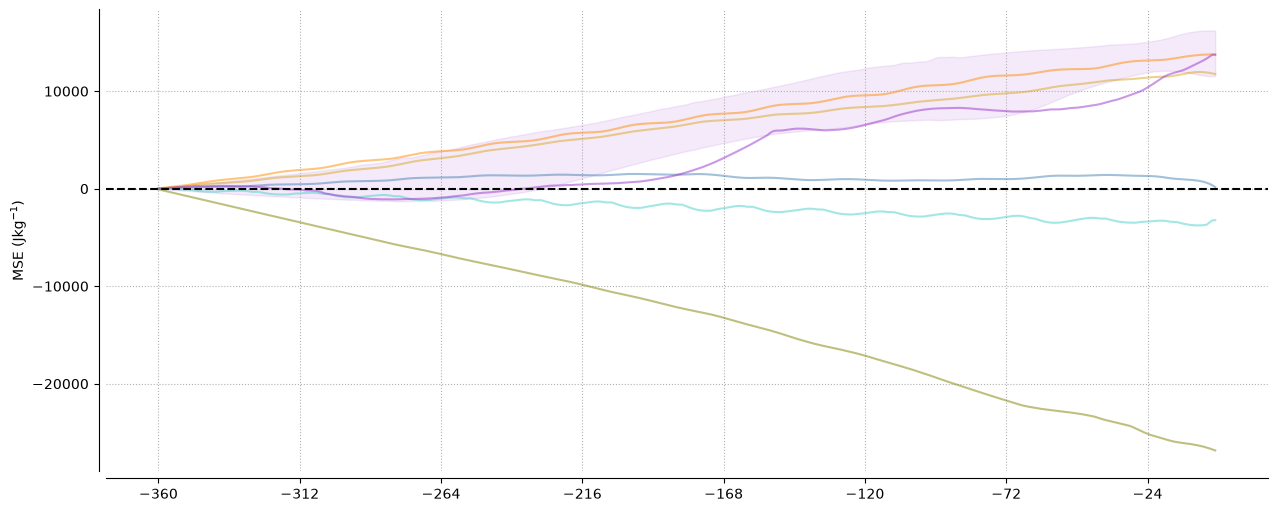

In [151]:
# for a single release
j=0
fig, ax = plt.subplots(1, 1, figsize=(15,6))

lh_flux, = ax.plot(x, per_rel_lh[j], color='goldenrod',
                   linestyle='-', alpha=0.5, label='LH term from sfc fluxes')
sh_flux, = ax.plot(x, per_rel_sh[j], color='steelblue',
                   linestyle='-', alpha=0.5, label='SH term from sfc fluxes')

s_rad, = ax.plot(x, per_rel_sw[j], color='darkorange',
                   linestyle='-', alpha=0.5, label='SW rad')
l_rad, = ax.plot(x, per_rel_lw[j], color='olive',
                   linestyle='-', alpha=0.5, label='LW rad')

se, = ax.plot(x, per_rel_seas[j], color='mediumturquoise',
                   linestyle='-', alpha=0.5, label='Seasonality')

adv, = ax.plot(x, per_rel_adv[j], color='darkorchid',
                   linestyle='-', alpha=0.5, label='Aadvection')
ax.fill_between(x, np.array(per_rel_adv).mean(axis=0) - np.array(per_rel_adv).std(axis=0),
                np.array(per_rel_adv).mean(axis=0) + np.array(per_rel_adv).std(axis=0), color='darkorchid', alpha=0.1) 

#calc, = ax.plot(x, per_rel_sw[j] + per_rel_lw[j]+ per_rel_sh[j] + per_rel_lh[j], 
#                color='grey', linestyle='--', label='Calculated')

ax.set_ylabel('MSE (Jkg$^{-1}$)')

# make it prettier
ax.grid(linestyle=':')
ax.axhline(0, linestyle='--', color='k')

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))
ax.set_xticks(x[0::48])

#fig.legend(handles = [season, adv, lh_flux, sh_flux, s_rad, l_rad, an_tot, calc], 
#           ncols=3, bbox_to_anchor=(0.3, 0.28, 0.4, 0.), frameon=True, framealpha=1)

#fig.savefig('rel_terms_temporal.png')
fig.show()

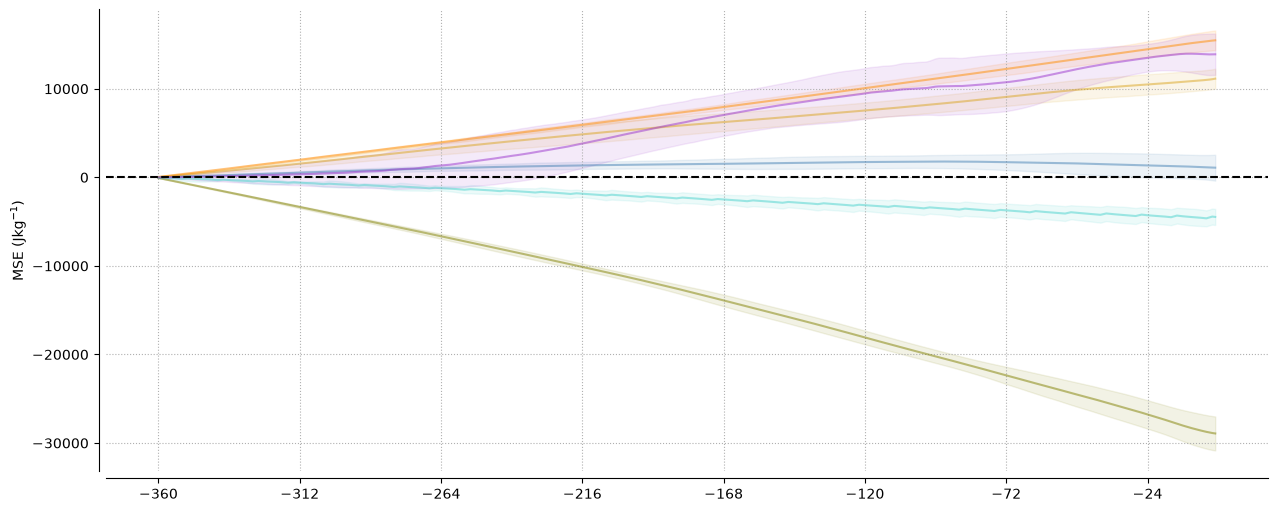

In [152]:
# on average over releases
fig, ax = plt.subplots(1, 1, figsize=(15,6))


lh_flux, = ax.plot(x, np.array(per_rel_lh).mean(axis=0), color='goldenrod',
                   linestyle='-', alpha=0.5, label='LH term from sfc fluxes')
ax.fill_between(x, np.array(per_rel_lh).mean(axis=0) - np.array(per_rel_lh).std(axis=0),
                np.array(per_rel_lh).mean(axis=0) + np.array(per_rel_lh).std(axis=0), color='goldenrod', alpha=0.1)
sh_flux, = ax.plot(x, np.array(per_rel_sh).mean(axis=0), color='steelblue',
                   linestyle='-', alpha=0.5, label='SH term from sfc fluxes')
ax.fill_between(x, np.array(per_rel_sh).mean(axis=0) - np.array(per_rel_sh).std(axis=0),
                np.array(per_rel_sh).mean(axis=0) + np.array(per_rel_sh).std(axis=0), color='steelblue', alpha=0.1) 

s_rad, = ax.plot(x, np.array(per_rel_sw).mean(axis=0), color='darkorange',
                   linestyle='-', alpha=0.5, label='SW rad')
ax.fill_between(x, np.array(per_rel_sw).mean(axis=0) - np.array(per_rel_sw).std(axis=0),
                np.array(per_rel_sw).mean(axis=0) + np.array(per_rel_sw).std(axis=0), color='darkorange', alpha=0.1)    

l_rad, = ax.plot(x, np.array(per_rel_lw).mean(axis=0), color='olive',
                   linestyle='-', alpha=0.5, label='LW rad')
ax.fill_between(x, np.array(per_rel_lw).mean(axis=0) - np.array(per_rel_lw).std(axis=0),
                np.array(per_rel_lw).mean(axis=0) + np.array(per_rel_lw).std(axis=0), color='olive', alpha=0.1) 

se, = ax.plot(x, np.array(per_rel_seas).mean(axis=0), color='mediumturquoise',
                   linestyle='-', alpha=0.5, label='Seasonality')
ax.fill_between(x, np.array(per_rel_seas).mean(axis=0) - np.array(per_rel_seas).std(axis=0),        
                np.array(per_rel_seas).mean(axis=0) + np.array(per_rel_seas).std(axis=0), color='mediumturquoise', alpha=0.1)

adv, = ax.plot(x, np.array(per_rel_adv).mean(axis=0), color='darkorchid',
                   linestyle='-', alpha=0.5, label='Aadvection')
ax.fill_between(x, np.array(per_rel_adv).mean(axis=0) - np.array(per_rel_adv).std(axis=0),
                np.array(per_rel_adv).mean(axis=0) + np.array(per_rel_adv).std(axis=0), color='darkorchid', alpha=0.1)  

#calc, = ax.plot(x, per_rel_sw[j] + per_rel_lw[j]+ per_rel_sh[j] + per_rel_lh[j], 
#                color='grey', linestyle='--', label='Calculated')

ax.set_ylabel('MSE (Jkg$^{-1}$)')

# make it prettier
ax.grid(linestyle=':')
ax.axhline(0, linestyle='--', color='k')

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))
ax.set_xticks(x[0::48])

#fig.legend(handles = [season, adv, lh_flux, sh_flux, s_rad, l_rad, an_tot, calc], 
#           ncols=3, bbox_to_anchor=(0.3, 0.28, 0.4, 0.), frameon=True, framealpha=1)

#fig.savefig('rel_terms_temporal.png')
fig.show()

### initial conds

In [153]:
# select initial condition data
init_per_release = rel_init_conds.sel(component='MSE')['grid_normalized_Jkg'].values
init_anomaly = rel_init_conds['init_anom'].values

### diagnose

In [154]:
partinit['amsl'] = partinit['to'] + partinit['z']

In [155]:
partinit['mse'] = partinit['T'] * cp + partinit['sh'] * Lv + partinit['amsl'] * g

In [156]:
diagnosed_partinit = [partinit['mse'].sel(particle=slice(rel*n+1, rel*n+n)).mean(dim='particle') for rel in range(no_of_rel)][::-1]

### split diagnose in climatology and anomaly

In [157]:
# shift longitude of climatology values into 0-360 range (from -180 - 180)
clim = clim.assign_coords(longitude=(clim['longitude'] % 360)).sortby('longitude')

# what is being done here?
clim = clim.squeeze('time', drop=True)

In [158]:
# ----------------------------------------------------------------------
# 1. Prepare the climatology
# ----------------------------------------------------------------------
buffer = 2          # degrees lat/lon
z_buffer = 500      # metres

lon_p = (partinit['lon'] % 360).values
lat_p = partinit['lat'].values
z_p   = partinit['amsl'].values


# crop to the trajectory extent (clim latitudes are descending)
clim_c = clim['mse'].sel(
    latitude=slice(lat_p.max() + buffer, lat_p.min() - buffer),
    longitude=slice(lon_p.min() - buffer, lon_p.max() + buffer),
    height=slice(max(z_p.min() - z_buffer, 0), z_p.max() + z_buffer),
)

# interpn wants ascending coords, and a fixed dim order
clim_c = (
    clim_c.sortby(['dayofyear', 'hour', 'height', 'latitude', 'longitude'])
          .transpose('dayofyear', 'hour', 'height', 'latitude', 'longitude')
          .load()   # cropped clim is small (a few hundred MB at most)
)

# merge (dayofyear, hour) into one continuous time axis in "hours since Jan 1"
doy_vals  = clim_c['dayofyear'].values
hour_vals = clim_c['hour'].values
n_doy, n_hr = len(doy_vals), len(hour_vals)

t_clim = ((doy_vals[:, None] - 1) * 24 + hour_vals[None, :]).ravel().astype('float64')
period = float(doy_vals.max() * 24)   # 8784 for 366 days, 8760 for 365

data = clim_c.values.reshape(n_doy * n_hr, *clim_c.shape[2:])

# pad one step on each side so interpolation wraps around the year boundary
data_pad = np.concatenate([data[-1:], data, data[:1]], axis=0)
t_pad = np.concatenate([[t_clim[-1] - period], t_clim, [t_clim[0] + period]])

clim_t = xr.DataArray(
    data_pad,
    dims=('t', 'height', 'latitude', 'longitude'),
    coords={
        't': t_pad,
        'height': clim_c['height'].values,
        'latitude': clim_c['latitude'].values,
        'longitude': clim_c['longitude'].values,
    },
    name='mse',
)

# ----------------------------------------------------------------------
# 2. Build the particle-time axis on the same scale
# ----------------------------------------------------------------------
time = partinit['time'].dt
t_p = ((time.dayofyear.values - 1) * 24
       + time.hour.values
       + time.minute.values / 60
       + time.second.values / 3600).astype('float64')

# ----------------------------------------------------------------------
# 3. Interpolate (pointwise: all indexers share the 'particle' dim)
# ----------------------------------------------------------------------
def pt(values):
    return xr.DataArray(values, dims='particle')

mse_clim_diag = clim_t.interp(
    t=pt(t_p),
    height=pt(z_p),
    latitude=pt(lat_p),
    longitude=pt(lon_p),
    kwargs={"fill_value": None},   # linear extrapolation outside the grid
)

# ----------------------------------------------------------------------
# 4. Attach to trajectory data and compute anomaly
# ----------------------------------------------------------------------
partinit['mse_clim'] = ('particle', mse_clim_diag.values.astype('float32'))
partinit['mse_anomaly'] = partinit['mse'] - partinit['mse_clim']

# sanity check
print('NaNs in mse_clim:', int(partinit['mse_clim'].isnull().sum().item()))
print(partinit[['mse', 'mse_clim', 'mse_anomaly']].to_dataframe().describe())

NaNs in mse_clim: 0
                mse      mse_clim   mse_anomaly
count  4.800000e+06  4.800000e+06  4.800000e+06
mean   2.850973e+05  2.832194e+05  1.877889e+03
std    2.814985e+03  1.498261e+03  2.859487e+03
min    2.784427e+05  2.792202e+05 -4.940938e+03
25%    2.828953e+05  2.821717e+05 -2.918438e+02
50%    2.848906e+05  2.831215e+05  1.189969e+03
75%    2.869127e+05  2.841966e+05  4.097969e+03
max    2.954267e+05  2.903928e+05  1.151425e+04


In [159]:
diagnosed_partinit_clim = [partinit['mse_clim'].sel(particle=slice(rel*n+1, rel*n+n)).
                      mean(dim='particle') for rel in range(no_of_rel)][::-1]
diagnosed_partinit_anomaly = [partinit['mse_anomaly'].sel(particle=slice(rel*n+1, rel*n+n)).
                      mean(dim='particle') for rel in range(no_of_rel)][::-1]

### calculate

In [160]:
# save data
arrays = {
    'diag': diagnosed_partinit,
    'diag_anomaly': diagnosed_partinit_anomaly,
    'init': init_per_release,
    'init_anomaly': init_anomaly,
    'flux_lh': int_flux_lh,
    'flux_sh': int_flux_sh,
    'sw_rad': int_rad_sw,
    'lw_rad': int_rad_lw,
    'advection': int_adv,
    'seasonality': int_seas
}

ds_timeseries = xr.Dataset(
    {k: ('release_date', np.asarray(v)) for k, v in arrays.items()},
    coords={'release_date': reldates},
)

In [161]:
ds_timeseries['calc'] = ds_timeseries.init+ds_timeseries.flux_lh+ds_timeseries.flux_sh+ds_timeseries.sw_rad+ds_timeseries.lw_rad
ds_timeseries['calc_wo'] = ds_timeseries.init+ds_timeseries.flux_lh+ds_timeseries.flux_sh

### check

In [162]:
# calculate errors
abs_err = np.abs(ds_timeseries.calc-ds_timeseries.diag).mean()
rmse = np.sqrt(1/len(ds_timeseries.release_date) * np.sum((ds_timeseries.calc.values-ds_timeseries.diag.values)**2))

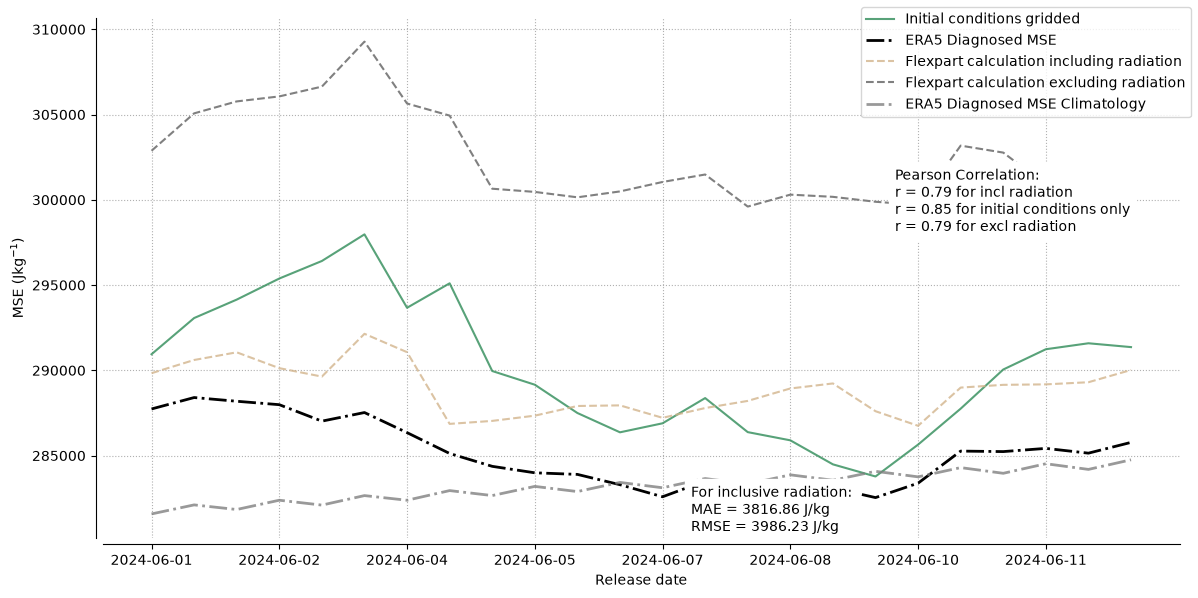

In [163]:
fig, ax = plt.subplots(1, 1, figsize=(12,6))

xes = ds_timeseries.release_date

l_init, = ax.plot(xes, ds_timeseries.init, color='seagreen', label='Initial conditions gridded', alpha=0.8)
l_diagnosed, = ax.plot(xes, ds_timeseries.diag, '-.k', linewidth=2, label='ERA5 Diagnosed MSE')
l_incl, = ax.plot(xes, ds_timeseries.calc, color='tan', linestyle='--', alpha=0.8, label='Flexpart calculation including radiation')
l_incl, = ax.plot(xes, ds_timeseries.calc_wo, color='grey', linestyle='--', label='Flexpart calculation excluding radiation')
l_diag_clim = ax.plot(xes, ds_timeseries.diag - ds_timeseries.diag_anomaly, '-.', color='grey', alpha=0.8, linewidth=2, label='ERA5 Diagnosed MSE Climatology')


ax.set_ylabel('MSE (Jkg$^{-1}$)')
ax.set_xticks(xes[::3])
ax.set_xlabel('Release date')
#ax.set_ylim(285000, 330000)

# make prettier
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))
ax.grid(linestyle=':')
#fig.legend(ncols=2, handles=[l_init, l_diagnosed, l_excl, l_incl],
#           bbox_to_anchor=(0.25, 0.2, 0.3, 0.), frameon=True, framealpha=1)

fig.text(
    x=0.75, y=0.62,
    s=(f'Pearson Correlation:\n'
       f'r = {np.corrcoef(ds_timeseries.calc, ds_timeseries.diag)[0,1]:.2f} for incl radiation\n'
       f'r = {np.corrcoef(ds_timeseries.init, ds_timeseries.diag)[0,1]:.2f} for initial conditions only\n'
       f'r = {np.corrcoef(ds_timeseries.calc_wo, ds_timeseries.diag)[0,1]:.2f} for excl radiation'),
    backgroundcolor='white',
)

fig.text(x=0.58, y=0.12, s=f'For inclusive radiation:\nMAE = {abs_err:.2f} J/kg\nRMSE = {rmse:.2f} J/kg',
        backgroundcolor='white')

fig.legend()
fig.tight_layout()

#fig.savefig('tsr_rad.png')

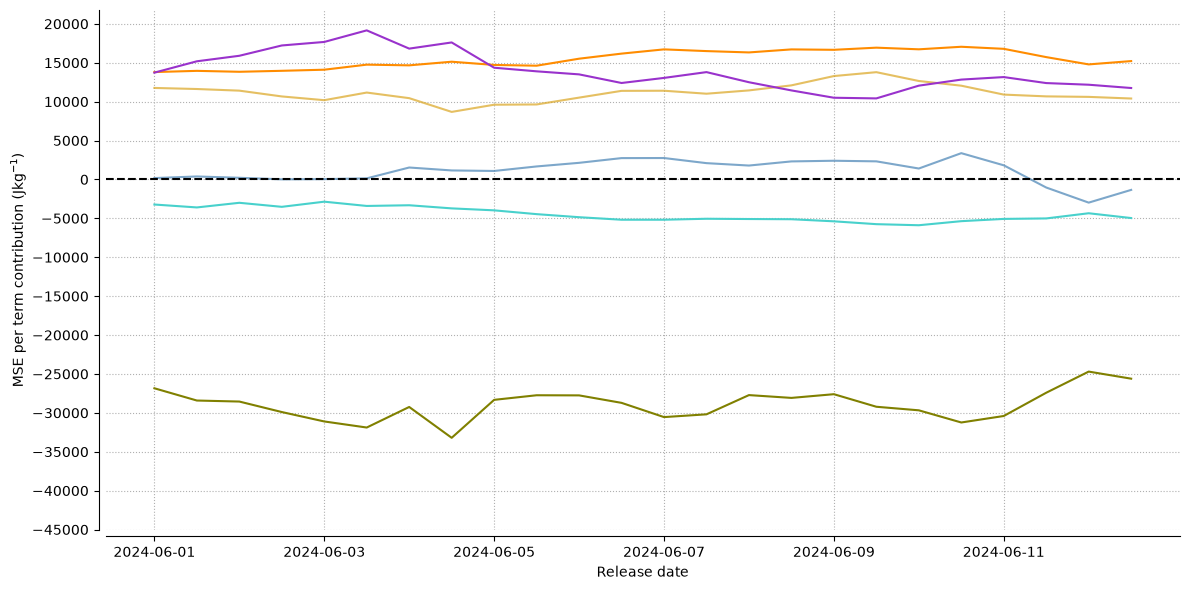

In [164]:
# single terms
fig, ax = plt.subplots(1, 1, figsize=(12,6))

int_f_lh, = ax.plot(xes, ds_timeseries.flux_lh, color='goldenrod', alpha=0.7, 
                    linestyle='-', label='LH term from sfc fluxes')
int_f_sh, = ax.plot(xes, ds_timeseries.flux_sh, color='steelblue', alpha=0.7, 
                    linestyle='-', label='LH term from sfc fluxes')

int_s_rad, = ax.plot(xes, ds_timeseries.sw_rad, color='darkorange', label='SW radiation')
int_l_rad, = ax.plot(xes, ds_timeseries.lw_rad, color='olive', label='LW radiation')
int_adve, = ax.plot(xes, ds_timeseries.advection, color='darkorchid', label='Advection')
int_s, = ax.plot(xes, ds_timeseries.seasonality, color='mediumturquoise', label='Seasonality')
#int_rad, = ax.plot(x, data.all_rad, color='tan', label='Total radiative cooling')

ax.set_ylabel('MSE per term contribution (Jkg$^{-1}$)')
ax.set_xticks(xes[::4])
ax.set_xlabel('Release date')

#ax.set_ylim(-46000, 22000)
ax.set_yticks(np.arange(-45000, 21000, 5000))

ax.axhline(0, linestyle='--', color='k')

# make prettier
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))
ax.grid(linestyle=':')

fig.tight_layout()
#fig.savefig('allterms.png')

In [165]:
# initial and diagnosed climatological values
init_clim = ds_timeseries.init - ds_timeseries.init_anomaly
diag_clim = ds_timeseries.diag - ds_timeseries.diag_anomaly

In [166]:
# residual from advection and seasonality terms from the calculation
clim_res = (init_clim - diag_clim) - (ds_timeseries.seasonality + ds_timeseries.advection)

In [167]:
clim_res

<xarray.DataArray (release_date: 24)> Size: 192B
array([ 313.26330181,   89.50716795,  108.91698622,  -30.10956778,
         89.6747082 ,  146.93816909,  -17.94166524,  -48.44431686,
         12.78584132,  -84.23236028, -152.12410094, -136.35153395,
         -5.82181503,  -92.67960483,   39.04355228,  107.05507918,
        193.16809923,  159.53621239,   62.10845094,  -41.5258648 ,
         31.3947679 ,   70.32905111,  147.85452827,   11.04152045])
Coordinates:
  * release_date  (release_date) datetime64[ns] 192B 2024-06-01 ... 2024-06-1...

In [168]:
# diagnosed anomaly
diagnosed_anom = ds_timeseries.diag_anomaly

In [169]:
# calculated anomaly with method like described in the thesis
calc_anom = ds_timeseries.init_anomaly + ds_timeseries.seasonality + ds_timeseries.advection + ds_timeseries.flux_lh + ds_timeseries.flux_sh + ds_timeseries.sw_rad + ds_timeseries.lw_rad

In [170]:
calc_anom

<xarray.DataArray (release_date: 24)> Size: 192B
array([7939.73932814, 8407.62185653, 9108.96891724, 7774.28903868,
       7446.08476405, 9339.92902612, 8700.46927605, 3960.07589956,
       4365.59990339, 4231.65421123, 5169.671133  , 4654.57388393,
       4106.98934274, 4227.1440557 , 4837.20806647, 4957.2147006 ,
       5482.70983822, 3364.58146564, 2932.15513426, 4734.39666265,
       5155.97460526, 4583.93880842, 4964.15397998, 5255.48751236])
Coordinates:
  * release_date  (release_date) datetime64[ns] 192B 2024-06-01 ... 2024-06-1...

In [171]:
# residual from method like described in the thesis
diagnosed_anom - calc_anom

<xarray.DataArray (release_date: 24)> Size: 192B
array([-1784.23346877, -2112.78738387, -2760.87223755, -2172.3041754 ,
       -2523.15947108, -4469.6795144 , -4735.65653191, -1784.00802846,
       -2652.13493757, -3434.65592021, -4162.90379902, -4788.78884975,
       -4635.33913522, -4374.85319267, -5141.57937384, -5377.5985507 ,
       -5933.79455502, -4906.03568928, -3302.52906614, -3765.46996587,
       -3882.62841385, -3684.45479963, -4011.41557666, -4234.40560318])
Coordinates:
  * release_date  (release_date) datetime64[ns] 192B 2024-06-01 ... 2024-06-1...

In [172]:
# residual from method with initial conditions alone
ds_timeseries.diag - ds_timeseries.calc

<xarray.DataArray (release_date: 24)> Size: 192B
array([-2097.50214167, -2202.28551862, -2869.79190932, -2142.17971505,
       -2612.82246053, -4616.61719521, -4717.71511081, -1735.56957098,
       -2664.91699471, -3350.42185094, -4010.76627035, -4652.44109998,
       -4629.51127771, -4282.18320087, -5180.62661875, -5484.64477978,
       -6126.97168745, -5065.58642804, -3364.6385852 , -3723.93329784,
       -3914.02562316, -3754.79910953, -4159.25850825, -4245.4352828 ])
Coordinates:
  * release_date  (release_date) datetime64[ns] 192B 2024-06-01 ... 2024-06-1...

In [173]:
rmse

np.float64(3986.23248376421)

In [174]:
ds_timeseries

<xarray.Dataset> Size: 2kB
Dimensions:       (release_date: 24)
Coordinates:
  * release_date  (release_date) datetime64[ns] 192B 2024-06-01 ... 2024-06-1...
Data variables:
    diag          (release_date) float32 96B 2.877e+05 2.884e+05 ... 2.858e+05
    diag_anomaly  (release_date) float32 96B 6.156e+03 6.295e+03 ... 1.021e+03
    init          (release_date) float64 192B 2.909e+05 2.931e+05 ... 2.914e+05
    init_anomaly  (release_date) float64 192B -1.449e+03 -718.1 ... -189.4
    flux_lh       (release_date) float32 96B 1.176e+04 1.162e+04 ... 1.04e+04
    flux_sh       (release_date) float32 96B 173.7 381.2 ... -1.345e+03
    sw_rad        (release_date) float32 96B 1.38e+04 1.396e+04 ... 1.521e+04
    lw_rad        (release_date) float32 96B -2.684e+04 ... -2.561e+04
    advection     (release_date) float32 96B 1.372e+04 1.518e+04 ... 1.175e+04
    seasonality   (release_date) float32 96B -3.225e+03 ... -4.964e+03
    calc          (release_date) float64 192B 2.898e+05 2.906e+05 ... 2.9e+05
    calc_wo       (release_date) float64 192B 3.029e+05 3.051e+05 ... 3.004e+05

In [175]:
ds_timeseries.to_netcdf('/jetfs/scratch/psplechtna/thesisdata/' + run + '_tsr.nc')